# GPU-Based Histogram Equalization

This notebook evaluates histogram equalization using CPU computing with Numba and GPU computing with Numba CUDA on an NVIDIA Tesla T4.

The experiments cover:

- Correctness using a real grayscale image.
- CPU and GPU performance across different image resolutions.
- GPU thread-block configuration.
- GPU memory transfer performance.
- GPU utilization, memory usage, and power monitoring.

A real image is used for visual correctness demonstration. Synthetic images are used for repeatable performance benchmarks.

## 1. GPU Environment and Libraries

The experiments use Google Colab with an NVIDIA Tesla T4 GPU.

Numba CUDA is used to implement the GPU-based histogram equalization. NumPy and Numba are used for the CPU implementation, while Pandas and Matplotlib are used for result analysis and visualization.

The CUDA environment and GPU availability are verified before executing the experiments.

In [4]:
!nvidia-smi

!pip -q install numba-cuda[cu13] scikit-image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import math
import os
import subprocess
import threading

from numba import cuda, njit
from skimage import data

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Numba version:", __import__("numba").__version__)

print("CUDA available:", cuda.is_available())

if cuda.is_available():
    print("GPU:", cuda.get_current_device().name)
else:
    raise RuntimeError("CUDA GPU is not available.")

Sun Nov 15 06:47:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             29W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Histogram Equalization

Histogram equalization is an image-processing technique used to improve image contrast.

It works by redistributing the intensity values of an image using its cumulative histogram distribution. This helps spread frequently occurring intensity values across a wider range.

For an 8-bit grayscale image, pixel intensities range from 0 to 255. A histogram containing 256 bins is calculated to represent the frequency of each intensity value.

The cumulative distribution function (CDF) is then used to construct a lookup table (LUT), which maps the original intensity values to their equalized values.

The transformation is given by:

`s_k = ((CDF(r_k) - CDF_min) / (N - CDF_min)) * (L - 1)`

where:

- `r_k` represents an original intensity value.
- `s_k` represents the corresponding equalized intensity.
- `CDF(r_k)` is the cumulative distribution function.
- `CDF_min` is the first non-zero cumulative histogram value.
- `N` is the total number of pixels.
- `L` is the number of possible intensity levels (256 for an 8-bit image).

The CPU and GPU implementations use the same histogram calculation, CDF transformation, and rounding method to ensure consistent results.

In [5]:
NUM_BINS = 256
INTENSITY_LEVELS = 256

print("Number of histogram bins:", NUM_BINS)
print("Number of intensity levels:", INTENSITY_LEVELS)

Number of histogram bins: 256
Number of intensity levels: 256


## 3. CPU Implementation

The CPU implementation performs histogram equalization using Numba.

First, a histogram is calculated using the pixel intensity values. The cumulative distribution function is then computed from the histogram.

A lookup table is constructed using the normalized cumulative distribution. Finally, each input pixel is replaced with its corresponding equalized intensity value.

The implementation uses a 256-bin histogram and supports 8-bit grayscale images.

In [6]:
@njit
def histogram_equalization_cpu(image):

    height, width = image.shape

    # Calculate the image histogram
    histogram = np.zeros(256, dtype=np.int64)

    for y in range(height):
        for x in range(width):
            pixel = image[y, x]
            histogram[pixel] += 1

    # Calculate cumulative distribution
    cdf = np.cumsum(histogram)

    # Find the first non-zero CDF value
    cdf_min = 0

    for i in range(256):
        if histogram[i] > 0:
            cdf_min = cdf[i]
            break

    total_pixels = height * width
    denominator = total_pixels - cdf_min

    # Construct lookup table
    lut = np.zeros(256, dtype=np.uint8)

    if denominator == 0:
        for i in range(256):
            lut[i] = i
    else:
        for i in range(256):
            numerator = (cdf[i] - cdf_min) * 255
            value = (numerator + denominator // 2) // denominator
            value = min(max(value, 0), 255)
            lut[i] = value

    # Apply lookup table
    output = np.empty((height, width), dtype=np.uint8)

    for y in range(height):
        for x in range(width):
            output[y, x] = lut[image[y, x]]

    return output

## 4. GPU Implementation Using Numba CUDA

The GPU implementation performs histogram equalization using multiple CUDA kernels.

The computation is divided into three main stages:

1. **Histogram Calculation:** CUDA threads process image pixels in parallel and update the corresponding histogram bins using atomic operations.
2. **CDF and Lookup Table Generation:** A CUDA thread calculates the cumulative histogram and constructs the lookup table.
3. **Image Equalization:** CUDA threads apply the lookup table to image pixels in parallel.

A two-dimensional CUDA grid is used to distribute image pixels across GPU threads.

The GPU implementation uses the same 256-bin histogram and transformation method as the CPU implementation.

In [7]:
@cuda.jit
def clear_histogram_kernel(histogram):
    idx = cuda.grid(1)
    if idx < 256:
        histogram[idx] = 0


@cuda.jit
def histogram_kernel(image, histogram, height, width):
    y, x = cuda.grid(2)
    if y < height and x < width:
        pixel = image[y, x]
        cuda.atomic.add(histogram, pixel, 1)


@cuda.jit
def cdf_lut_kernel(histogram, lut, total_pixels):
    if cuda.grid(1) == 0:
        cdf = 0
        cdf_min = 0

        # Find the first non-zero CDF value
        for i in range(256):
            cdf += histogram[i]
            if cdf_min == 0 and histogram[i] > 0:
                cdf_min = cdf

        denominator = total_pixels - cdf_min

        if denominator == 0:
            for i in range(256):
                lut[i] = i
        else:
            cdf = 0
            for i in range(256):
                cdf += histogram[i]
                numerator = (cdf - cdf_min) * 255
                value = (numerator + denominator // 2) // denominator
                if value < 0:
                    value = 0
                if value > 255:
                    value = 255
                lut[i] = value


@cuda.jit
def equalize_image_kernel(image, output, lut, height, width):
    y, x = cuda.grid(2)
    if y < height and x < width:
        pixel = image[y, x]
        output[y, x] = lut[pixel]

In [8]:
def launch_gpu_pipeline(d_image, d_output, d_histogram, d_lut, height, width, threads=(16, 16)):
    blocks = ((height + threads[0] - 1) // threads[0], (width + threads[1] - 1) // threads[1])

    # Initialize histogram
    clear_histogram_kernel[1, 256](d_histogram)

    # Calculate histogram
    histogram_kernel[blocks, threads](d_image, d_histogram, height, width)

    # Generate cumulative distribution and lookup table
    cdf_lut_kernel[1, 1](d_histogram, d_lut, height * width)

    # Apply histogram equalization
    equalize_image_kernel[blocks, threads](d_image, d_output, d_lut, height, width)


def histogram_equalization_gpu(image, threads_per_block=(16, 16)):
    image = np.ascontiguousarray(image, dtype=np.uint8)
    height, width = image.shape

    # Transfer input image to GPU
    d_image = cuda.to_device(image)

    # Allocate output and histogram memory
    d_output = cuda.device_array((height, width), dtype=np.uint8)
    d_histogram = cuda.device_array(256, dtype=np.int32)
    d_lut = cuda.device_array(256, dtype=np.uint8)

    # Execute GPU pipeline
    launch_gpu_pipeline(d_image, d_output, d_histogram, d_lut, height, width, threads_per_block)
    cuda.synchronize()

    return d_output.copy_to_host()

## 5. Histogram Equalization on a Real Image

A real grayscale image from the scikit-image sample dataset is used to demonstrate histogram equalization.

The same image is processed using CPU and GPU implementations.

The outputs are compared numerically and visually to verify that both implementations produce equivalent results.

The original and equalized histograms are also visualized to demonstrate the change in intensity distribution.

In [9]:
# Load the same real grayscale image used in Sobel and Gaussian Blur
real_image = data.camera()

# Ensure 8-bit grayscale format
real_image = np.ascontiguousarray(real_image, dtype=np.uint8)

# CPU processing
cpu_real_equalized = histogram_equalization_cpu(real_image)

# GPU processing
gpu_real_equalized = histogram_equalization_gpu(real_image)

# Correctness verification
max_difference = np.max(np.abs(cpu_real_equalized.astype(np.int16) - gpu_real_equalized.astype(np.int16)))
outputs_match = np.array_equal(cpu_real_equalized, gpu_real_equalized)

print("Image shape:", real_image.shape)
print("Image data type:", real_image.dtype)
print("Maximum absolute difference:", max_difference)
print("CPU and GPU outputs match:", outputs_match)

if not outputs_match:
    raise AssertionError("CPU and GPU histogram equalization outputs do not match.")

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Image shape: (512, 512)
Image data type: uint8
Maximum absolute difference: 0
CPU and GPU outputs match: True


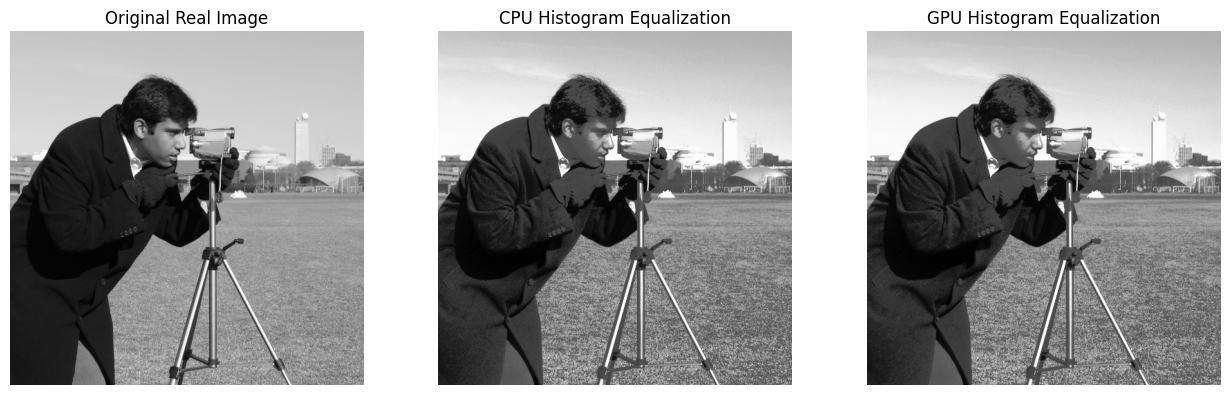

In [10]:
plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(real_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Real Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cpu_real_equalized, cmap="gray", vmin=0, vmax=255)
plt.title("CPU Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gpu_real_equalized, cmap="gray", vmin=0, vmax=255)
plt.title("GPU Histogram Equalization")
plt.axis("off")

plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)

plt.savefig("results/figures/histogram_equalization_real_image_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

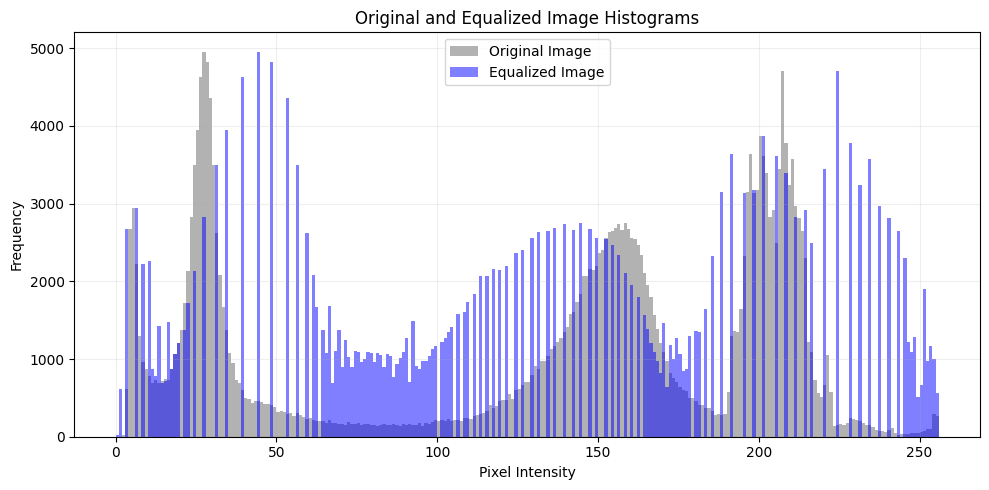

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(real_image.ravel(), bins=256, range=(0, 256), color="gray", alpha=0.6, label="Original Image")

plt.hist(cpu_real_equalized.ravel(), bins=256, range=(0, 256), color="blue", alpha=0.5, label="Equalized Image")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Original and Equalized Image Histograms")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig("results/figures/histogram_equalization_histograms.png", dpi=300, bbox_inches="tight")

plt.show()

## 6. Performance Across Different Image Resolutions

Repeatable synthetic grayscale images are generated at four resolutions:

- 256 × 256
- 512 × 512
- 1024 × 1024
- 2048 × 2048

For each resolution, the notebook measures:

- CPU execution time.
- GPU kernel execution time, excluding data transfers.
- GPU end-to-end execution time, including input transfer, output and intermediate memory allocation, kernel execution, and output transfer.

The same input image is used for CPU and GPU measurements at each resolution.

Warm-up executions are performed before timing to reduce the effect of CPU compilation, CUDA initialization, and kernel compilation overhead.

The GPU kernel measurement includes all histogram equalization stages: histogram initialization, histogram calculation, CDF and lookup table generation, and image equalization.

In [12]:
def benchmark_histogram_equalization(image, repetitions=20):
    image = np.ascontiguousarray(image, dtype=np.uint8)
    height, width = image.shape
    threads = (16, 16)
    blocks = ((height + threads[0] - 1) // threads[0], (width + threads[1] - 1) // threads[1])

    # CPU warm-up
    histogram_equalization_cpu(image)

    # GPU warm-up
    histogram_equalization_gpu(image, threads)
    cuda.synchronize()

    # CPU timing
    cpu_times = []

    for _ in range(repetitions):
        start = time.perf_counter()
        cpu_result = histogram_equalization_cpu(image)
        cpu_times.append(time.perf_counter() - start)

    cpu_avg_ms = np.mean(cpu_times) * 1000

    # GPU memory allocation for kernel-only timing
    d_image = cuda.to_device(image)
    d_output = cuda.device_array((height, width), dtype=np.uint8)
    d_histogram = cuda.device_array(256, dtype=np.int32)
    d_lut = cuda.device_array(256, dtype=np.uint8)

    # GPU pipeline warm-up
    launch_gpu_pipeline(d_image, d_output, d_histogram, d_lut, height, width, threads)
    cuda.synchronize()

    # GPU kernel timing
    start_event = cuda.event()
    end_event = cuda.event()
    start_event.record()

    for _ in range(50):
        launch_gpu_pipeline(d_image, d_output, d_histogram, d_lut, height, width, threads)

    end_event.record()
    end_event.synchronize()
    gpu_kernel_avg_ms = (cuda.event_elapsed_time(start_event, end_event) / 50)

    # GPU end-to-end timing
    total_times = []

    for _ in range(10):
        cuda.synchronize()
        start = time.perf_counter()
        gpu_result = histogram_equalization_gpu(image, threads)
        cuda.synchronize()
        total_times.append(time.perf_counter() - start)

    gpu_total_avg_ms = np.mean(total_times) * 1000

    # Correctness verification
    max_difference = np.max(np.abs(cpu_result.astype(np.int16) - gpu_result.astype(np.int16)))
    outputs_match = np.array_equal(cpu_result,gpu_result)

    return {
        "Resolution": f"{height}x{width}",
        "CPU (ms)": cpu_avg_ms,
        "GPU Kernel (ms)": gpu_kernel_avg_ms,
        "GPU End-to-End (ms)": gpu_total_avg_ms,
        "Kernel Speedup": cpu_avg_ms / gpu_kernel_avg_ms,
        "End-to-End Speedup": cpu_avg_ms / gpu_total_avg_ms,
        "Maximum Difference": max_difference,
        "Outputs Match": outputs_match
    }


resolutions = [256, 512, 1024, 2048]
results = []
correctness_results = []

for size in resolutions:
    print(f"Running {size} x {size} ...")
    rng = np.random.default_rng(42)
    test_image = rng.integers(0, 256, size=(size, size), dtype=np.uint8)
    result = benchmark_histogram_equalization(test_image, repetitions=20)
    results.append(result)
    correctness_results.append({
        "Resolution": result["Resolution"],
        "Outputs Match": result["Outputs Match"],
        "Maximum Difference": result["Maximum Difference"]
    })
    print(
        f"Completed: {size}x{size} | "
        f"Correctness: {result['Outputs Match']}"
    )

results_df = pd.DataFrame(results)
correctness_df = pd.DataFrame(correctness_results)
print("Performance comparison:")
display(results_df[["Resolution", "CPU (ms)", "GPU Kernel (ms)", "GPU End-to-End (ms)", "Kernel Speedup", "End-to-End Speedup"]].round(4))
print("Correctness verification:")
display(correctness_df.round(6))

Running 256 x 256 ...
Completed: 256x256 | Correctness: True
Running 512 x 512 ...
Completed: 512x512 | Correctness: True
Running 1024 x 1024 ...
Completed: 1024x1024 | Correctness: True
Running 2048 x 2048 ...
Completed: 2048x2048 | Correctness: True
Performance comparison:


,Resolution,CPU (ms),GPU Kernel (ms),GPU End-to-End (ms),Kernel Speedup,End-to-End Speedup
0,256x256,0.1156,0.2433,1.1657,0.4752,0.0992
1,512x512,0.3268,0.3590,1.2331,0.9103,0.2650
2,1024x1024,1.3094,0.9014,2.1927,1.4526,0.5972
3,2048x2048,4.9937,3.0652,5.5428,1.6292,0.9009


Correctness verification:


,Resolution,Outputs Match,Maximum Difference
0,256x256,True,0
1,512x512,True,0
2,1024x1024,True,0
3,2048x2048,True,0


## 7. GPU Memory Transfer Performance

GPU applications require data to be transferred between CPU memory and GPU memory.

This experiment measures two transfer operations separately:

- **Host-to-Device (H2D):** Transfer of the input image from CPU memory to GPU memory.
- **Device-to-Host (D2H):** Transfer of the processed output from GPU memory back to CPU memory.

Both measurements are performed using a 2048 × 2048 image.

The average transfer time is calculated over multiple runs.

In [13]:
# Prepare a repeatable 2048 x 2048 image
rng = np.random.default_rng(42)
transfer_image = rng.integers(0, 256, size=(2048, 2048), dtype=np.uint8)
transfer_runs = 100

# Allocate GPU memory before measuring transfers
d_transfer_input = cuda.device_array(transfer_image.shape, dtype=np.uint8)
d_transfer_output = cuda.device_array(transfer_image.shape, dtype=np.uint8)

# Initialize output memory before D2H measurement
d_transfer_output.copy_to_device(transfer_image)

# Warm-up transfers
d_transfer_input.copy_to_device(transfer_image)
d_transfer_output.copy_to_host()
cuda.synchronize()

# Measure Host-to-Device transfer
h2d_times = []

for _ in range(transfer_runs):
    cuda.synchronize()
    start = time.perf_counter()
    d_transfer_input.copy_to_device(transfer_image)
    cuda.synchronize()
    h2d_times.append(time.perf_counter() - start)

h2d_avg_ms = np.mean(h2d_times) * 1000

# Measure Device-to-Host transfer
d2h_times = []

for _ in range(transfer_runs):
    cuda.synchronize()
    start = time.perf_counter()
    output_cpu = d_transfer_output.copy_to_host()
    cuda.synchronize()
    d2h_times.append(time.perf_counter() - start)

d2h_avg_ms = np.mean(d2h_times) * 1000

print("GPU Memory Transfer Results")
print("---------------------------")
print("Image resolution: 2048 x 2048")
print("Average H2D transfer time:", round(h2d_avg_ms, 5), "ms")
print("Average D2H transfer time:", round(d2h_avg_ms, 5), "ms")

GPU Memory Transfer Results
---------------------------
Image resolution: 2048 x 2048
Average H2D transfer time: 1.08811 ms
Average D2H transfer time: 1.16626 ms


## 8. Thread-Block Configuration Comparison

The GPU histogram equalization pipeline is evaluated using three thread-block configurations:

- 8 × 8 threads
- 16 × 16 threads
- 32 × 32 threads

The same 512 × 512 real image is used for all configurations.

The experiment compares GPU kernel execution time and verifies the correctness of each configuration against the CPU output.

All stages of the GPU pipeline are included in the timing measurement.

In [14]:
thread_configs = [(8, 8), (16, 16), (32, 32)]
block_results = []
height, width = real_image.shape
real_image = np.ascontiguousarray(real_image, dtype=np.uint8)
cpu_block_output = histogram_equalization_cpu(real_image)

# Transfer input image to GPU
d_real_image = cuda.to_device(real_image)

# Allocate GPU memory
d_output = cuda.device_array(real_image.shape, dtype=np.uint8)
d_histogram = cuda.device_array(256, dtype=np.int32)
d_lut = cuda.device_array(256, dtype=np.uint8)

for threads in thread_configs:

    # Warm-up
    launch_gpu_pipeline(d_real_image, d_output, d_histogram, d_lut, height, width, threads)
    cuda.synchronize()
    start_event = cuda.event()
    end_event = cuda.event()
    start_event.record()

    for _ in range(100):
        launch_gpu_pipeline(d_real_image, d_output, d_histogram, d_lut, height, width, threads)

    end_event.record()
    end_event.synchronize()
    avg_time_ms = (cuda.event_elapsed_time(start_event, end_event) / 100)
    output = d_output.copy_to_host()
    outputs_match = np.array_equal(cpu_block_output, output)
    max_difference = np.max(np.abs(cpu_block_output.astype(np.int16) - output.astype(np.int16)))
    block_results.append({
        "Threads per Block": f"{threads[0]}x{threads[1]}",
        "Total Threads": threads[0] * threads[1],
        "GPU Kernel Time (ms)": avg_time_ms,
        "Outputs Match": outputs_match,
        "Maximum Difference": max_difference
    })

block_df = pd.DataFrame(block_results)
display(block_df.round(5))

,Threads per Block,Total Threads,GPU Kernel Time (ms),Outputs Match,Maximum Difference
0,8x8,64,0.22345,True,0
1,16x16,256,0.22837,True,0
2,32x32,1024,0.25626,True,0


## 9. Performance Graphs

The following graphs summarize the resolution benchmark:

- CPU versus GPU kernel execution time.
- CPU versus GPU end-to-end execution time.
- GPU kernel and end-to-end speedup across image resolutions.

These graphs help visualize the performance differences between CPU and GPU implementations and the effect of image resolution on execution time.

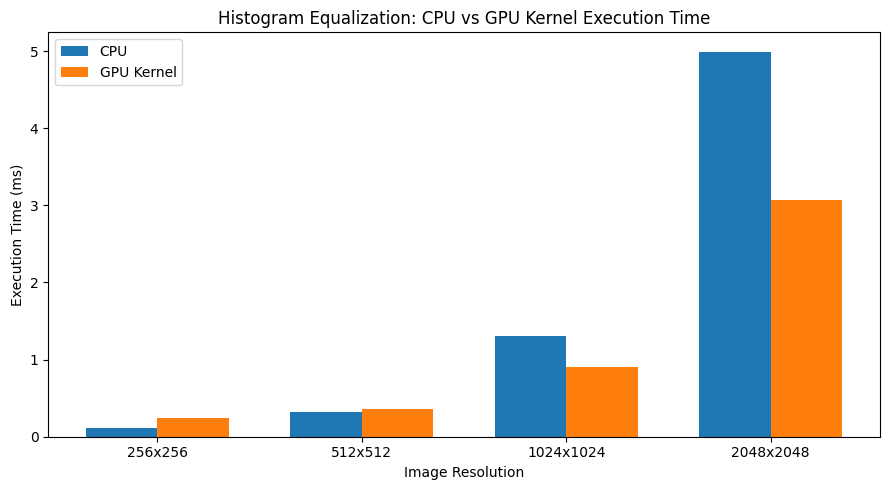

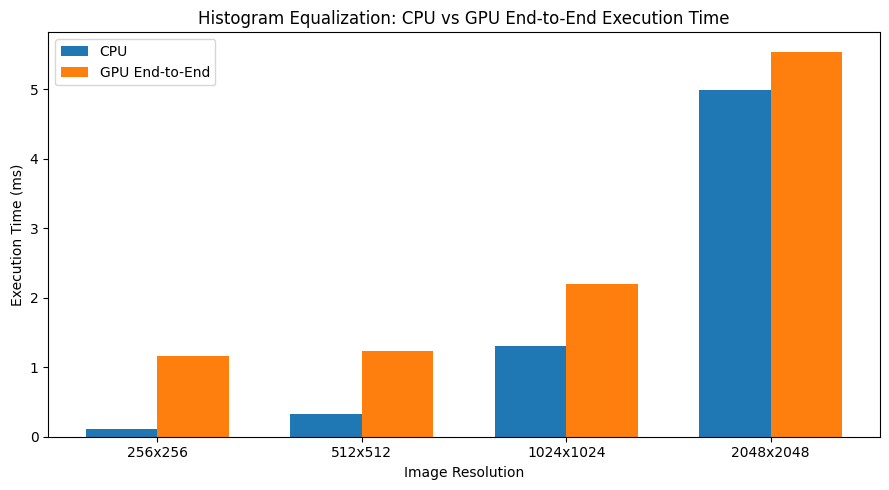

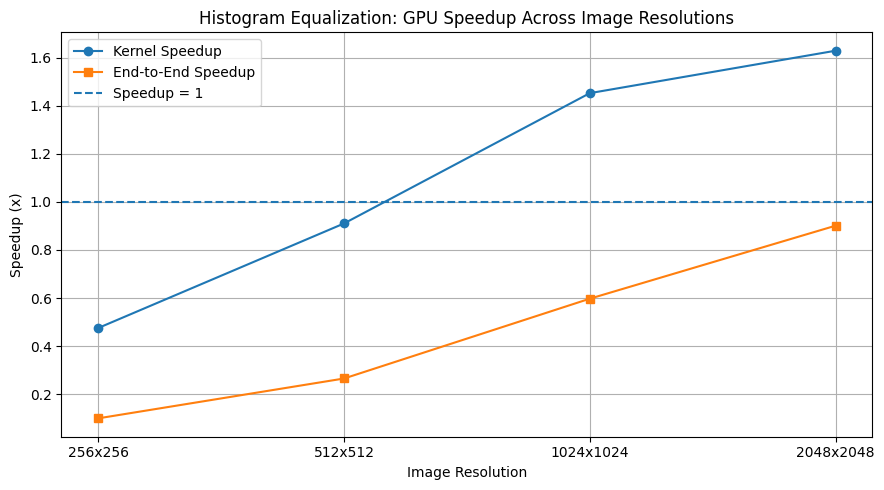

Performance graphs saved in results/figures/


In [15]:
os.makedirs("results/figures", exist_ok=True)

x = np.arange(len(results_df))
labels = results_df["Resolution"]
bar_width = 0.35

# CPU vs GPU kernel execution time
plt.figure(figsize=(9, 5))
plt.bar(x - bar_width / 2, results_df["CPU (ms)"], bar_width, label="CPU")
plt.bar(x + bar_width / 2, results_df["GPU Kernel (ms)"], bar_width, label="GPU Kernel")
plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("Histogram Equalization: CPU vs GPU Kernel Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/histogram_equalization_cpu_vs_gpu_kernel.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(x - bar_width / 2, results_df["CPU (ms)"], bar_width, label="CPU")
plt.bar(x + bar_width / 2, results_df["GPU End-to-End (ms)"], bar_width, label="GPU End-to-End")
plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("Histogram Equalization: CPU vs GPU End-to-End Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/histogram_equalization_cpu_vs_gpu_end_to_end.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(labels, results_df["Kernel Speedup"], marker="o", label="Kernel Speedup")
plt.plot(labels, results_df["End-to-End Speedup"], marker="s", label="End-to-End Speedup")
plt.axhline(y=1, linestyle="--", label="Speedup = 1")
plt.xlabel("Image Resolution")
plt.ylabel("Speedup (x)")
plt.title("Histogram Equalization: GPU Speedup Across Image Resolutions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/figures/histogram_equalization_gpu_speedup_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Performance graphs saved in results/figures/")

## 10. GPU Resource Utilization and Memory Monitoring

The GPU is monitored while the 2048 × 2048 histogram equalization workload is executed repeatedly.

Measurements include:

- GPU utilization.
- GPU memory usage.
- GPU power consumption.

The measurements are sampled periodically using NVIDIA System Management Interface (nvidia-smi).

A warm-up execution is performed before monitoring begins.

In [16]:
# Generate repeatable 2048 x 2048 input
monitor_image = np.random.default_rng(42).integers(0, 256, size=(2048, 2048), dtype=np.uint8)

# Warm-up before monitoring
histogram_equalization_gpu(monitor_image)
cuda.synchronize()
measurements = []
stop_monitoring = threading.Event()

def monitor_gpu():
    while not stop_monitoring.is_set():
        try:
            result = subprocess.run(["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total,power.draw", "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=2)
            if result.returncode == 0 and result.stdout.strip():
                values = [
                    value.strip()
                    for value in result.stdout.strip().split(",")
                ]
                measurements.append({
                    "GPU Utilization (%)": float(values[0]),
                    "Memory Used (MB)": float(values[1]),
                    "Total Memory (MB)": float(values[2]),
                    "Power Usage (W)": (
                        float(values[3])
                        if values[3] not in ["N/A", "[N/A]"]
                        else np.nan
                    )
                })

        except Exception:
            pass

        stop_monitoring.wait(0.1)


monitor_thread = threading.Thread(
    target=monitor_gpu
)

monitor_thread.start()

start_time = time.perf_counter()

for _ in range(100):

    monitor_output = histogram_equalization_gpu(
        monitor_image
    )

cuda.synchronize()

workload_time = time.perf_counter() - start_time

stop_monitoring.set()
monitor_thread.join()

df_active = pd.DataFrame(measurements)

print("Image resolution:", monitor_image.shape)
print("Number of histogram equalization executions:", 100)
print("Workload execution time:", round(workload_time, 3), "seconds")
print("Number of monitoring samples:", len(df_active))

if df_active.empty:

    print("No GPU monitoring samples were collected.")

else:

    display(df_active.describe().round(2))

Image resolution: (2048, 2048)
Number of histogram equalization executions: 100
Workload execution time: 0.5 seconds
Number of monitoring samples: 4


,GPU Utilization (%),Memory Used (MB),Total Memory (MB),Power Usage (W)
count,4.00,4.00,4.0,4.00
mean,29.50,132.00,15360.0,37.86
std,24.79,6.83,0.0,5.71
min,0.00,123.00,15360.0,32.32
25%,13.50,129.00,15360.0,35.10
50%,34.00,133.00,15360.0,36.64
75%,50.00,136.00,15360.0,39.39
max,50.00,139.00,15360.0,45.83


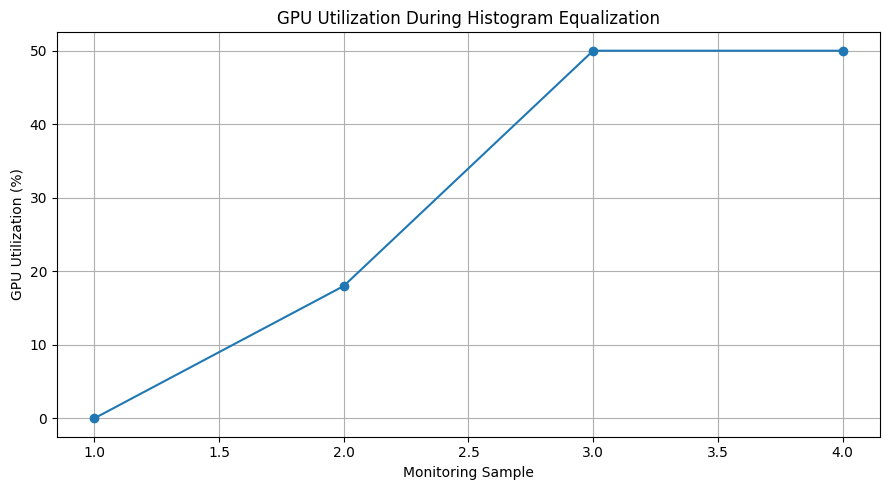

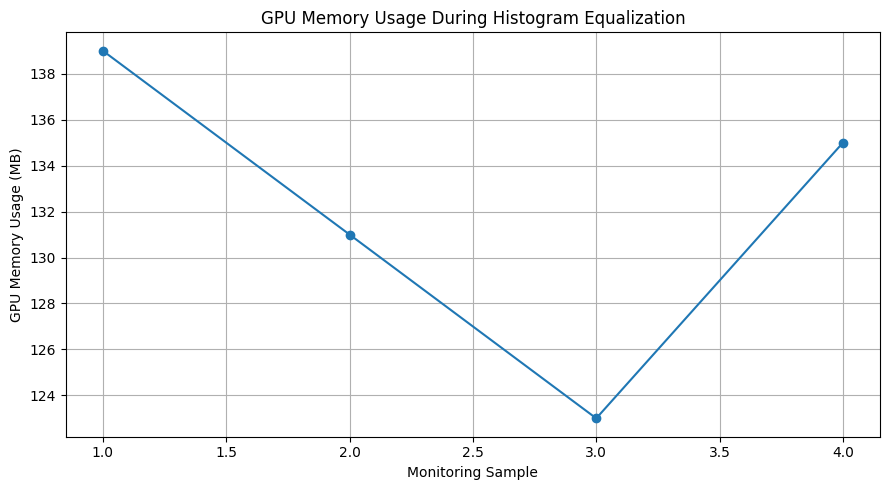

GPU resource monitoring graphs saved successfully.


In [17]:
if not df_active.empty:

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(df_active) + 1),
        df_active["GPU Utilization (%)"],
        marker="o"
    )

    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Utilization (%)")
    plt.title("GPU Utilization During Histogram Equalization")
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        "results/figures/histogram_equalization_gpu_utilization.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(df_active) + 1),
        df_active["Memory Used (MB)"],
        marker="o"
    )

    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Memory Usage (MB)")
    plt.title("GPU Memory Usage During Histogram Equalization")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("results/figures/histogram_equalization_gpu_memory.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("GPU resource monitoring graphs saved successfully.")
else:
    print("No resource graphs generated because no samples were collected.")

## 11. Results and Discussion

The histogram equalization workload was implemented using both CPU and GPU approaches and evaluated on a Tesla T4 GPU through Google Colab. The experiments focused on correctness, execution time, memory transfer overhead, thread-block configuration, and GPU resource utilization.

### 11.1 Correctness Analysis

The CPU and GPU implementations produced identical results for the real test image and all synthetic image resolutions.

For the 512 × 512 real image, the maximum absolute difference between the CPU and GPU outputs was 0. The same result was obtained for all synthetic resolutions: 256 × 256, 512 × 512, 1024 × 1024, and 2048 × 2048.

This confirms that the GPU implementation correctly performs histogram calculation, cumulative distribution computation, lookup table generation, and pixel intensity mapping.

### 11.2 CPU and GPU Performance Analysis

The performance comparison showed that GPU kernel execution becomes advantageous as image resolution increases.

At 256 × 256 and 512 × 512, the CPU implementation was faster than GPU kernel execution. At 1024 × 1024 and 2048 × 2048, the GPU kernel achieved speedups of approximately 1.45× and 1.63×, respectively.

However, the end-to-end GPU execution time was higher than the CPU execution time at all tested resolutions. This is mainly due to GPU memory allocation, data transfers, and the overhead of launching multiple CUDA kernels.

The highest kernel speedup of approximately 1.63× was observed at 2048 × 2048. The end-to-end speedup at this resolution was approximately 0.90×, indicating that the complete GPU execution was still slightly slower than the CPU implementation.

These observations demonstrate that kernel-level acceleration does not always result in an overall end-to-end performance improvement.

### 11.3 GPU Memory Transfer Analysis

For a 2048 × 2048 image, the average Host-to-Device (H2D) transfer time was approximately 1.088 ms, while the Device-to-Host (D2H) transfer time was approximately 1.166 ms.

These measurements highlight the additional overhead associated with transferring image data between CPU and GPU memory.

### 11.4 Thread-Block Configuration Analysis

Three thread-block configurations were evaluated: 8 × 8, 16 × 16, and 32 × 32.

The 8 × 8 configuration achieved the lowest measured kernel execution time of approximately 0.223 ms, followed closely by the 16 × 16 configuration at approximately 0.228 ms.

The 32 × 32 configuration recorded a higher execution time of approximately 0.256 ms.

All configurations produced identical outputs. The results indicate that smaller thread blocks performed slightly better for this implementation and tested workload.

### 11.5 GPU Resource Utilization Analysis

GPU resource utilization was monitored during 100 executions of histogram equalization on a 2048 × 2048 image.

The observed mean GPU utilization was approximately 29.50%, with memory usage averaging 132 MB. Average power consumption was approximately 37.86 W.

The monitoring results indicate that the workload used only a small portion of the available GPU memory. GPU utilization varied during execution, reflecting the relatively short duration and different computational stages of the workload.

Overall, the experiments demonstrate that GPU acceleration can improve the computational performance of histogram equalization for larger images, although memory transfer and kernel-launch overhead can limit end-to-end performance.

## 12. Experimental Limitations

The experiments were conducted using a Tesla T4 GPU in the Google Colab cloud environment. The following limitations should be considered when interpreting the results:

1. **Cloud Environment Variability:** GPU availability, resource allocation, and background workloads in Google Colab may influence execution times and resource utilization measurements.

2. **GPU Kernel Launch Overhead:** Histogram equalization requires multiple GPU kernels for histogram initialization, histogram calculation, CDF and lookup table generation, and pixel mapping. The overhead of launching these kernels affects overall performance, particularly for smaller images.

3. **Memory Transfer Overhead:** Input and output images must be transferred between CPU and GPU memory. These transfers contribute to end-to-end execution time and can reduce the benefits of GPU acceleration.

4. **Resource Monitoring Duration:** GPU resource utilization was measured during a relatively short workload execution. Only four monitoring samples were collected, so the reported averages provide indicative observations rather than a detailed representation of sustained GPU behavior.

5. **Limited Workload Configurations:** The experiments considered a fixed histogram size of 256 intensity levels and a limited number of image resolutions and thread-block configurations. Different image characteristics and GPU configurations may produce different performance results.

6. **Hardware Dependency:** The observed performance is specific to the Tesla T4 GPU and the software environment used in the experiments. Results may vary on other GPU architectures.

## 13. Conclusion

Histogram equalization was successfully implemented using both CPU and GPU approaches and evaluated using a Tesla T4 GPU in the Google Colab cloud environment.

The GPU implementation produced results identical to the CPU implementation for both real and synthetic images, confirming the correctness of the parallel histogram calculation, cumulative distribution computation, lookup table generation, and intensity mapping operations.

Performance experiments showed that GPU kernel execution became faster than CPU execution for larger image resolutions, achieving a maximum kernel speedup of approximately 1.63× at 2048 × 2048. However, end-to-end GPU execution remained slower than CPU execution across all tested resolutions because of memory transfer, allocation, and kernel-launch overhead.

Thread-block experiments showed that the 8 × 8 configuration provided the lowest measured execution time among the tested configurations. GPU resource monitoring also demonstrated that the workload used a relatively small amount of available GPU memory.

Overall, the experiment highlights both the advantages and limitations of GPU-based histogram equalization. Although parallel execution can improve computational performance for larger images, the overall benefit depends on the balance between computation, memory transfers, and execution overhead.